# Multi-Fidelity CoKriging Comparison: HF Sample Sweep (2D)

Sweeps the number of HF samples from 20 to 200 for `SurrogateModels.cokriging.CoKriging` on the 2D test function (`PeaksShifted2`), with 800 LF samples. This is the Kriging counterpart of `MultiFidelityCompare_MFNN.ipynb`. It uses the same LF samples, HF sample sets, and test points, so the errors compare directly.

- **LF model:** one `Kriging` model is fit to the LF samples and shared by every CoKriging fit, so the fits differ only in the HF samples.
- **HF samples:** each count is a Latin hypercube sample, drawn with 3 sampling seeds. The sets aren't nested: the 40-sample set doesn't contain the 20-sample set.
- **HF-only baseline:** a `Kriging` model with the same nugget is also fit to each HF sample set, so every CoKriging fit has a paired baseline on exactly the same samples.
- **Mean:** each sample set is fit with both of `CoKriging`'s mean options. `mean="separate"` (the default) gives each fidelity its own constant mean, `E[y_lf] = mu_c` and `E[y_hf] = rho * mu_c + mu_d`, as in Kennedy and O'Hagan. `mean="shared"` uses one constant mean for both, as in Forrester's formulation. This benchmark's LF function is offset by about -2 from the HF function, so the shared mean sits near the LF level and the HF predictions are pulled toward it between HF samples.
- **Seeds:** Kriging's optimizer uses fixed starting points, so both models are deterministic for a given sample set. Unlike the NN sweep there are no initialization seeds, and the sampling seed is the only source of spread.

With `scale_input=True`, `x` is scaled to [-1, 1] using the function's bounds. Neither model scales its outputs, so all errors are in original units. The whole sweep takes about a minute after the LF fit.

**Output:** `cokriging_hf_sweep_2d.csv` has the columns `points_lf, points_hf, hf_sample_seed, model, test_rmse, train_rmse, training_time`, where `model` is `cokriging_separate`, `cokriging_shared`, or `hf_only`. CoKriging's `training_time` leaves out the shared LF fit. Rerunning appends to the file.

In [1]:
%load_ext autoreload
%autoreload 2

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

import examples.multi_fidelity_functions as mfs
from examples import multi_fidelity_kriging_helpers as mf_kriging_helpers

### Data

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()

n_lf = 800
hf_points = range(20, 201, 20)
hf_sample_seeds = [0, 1, 2]
seed = 0
nugget = 1e-3

# One LF sample set and LF model are shared by every fit
X_lf = my_function.sample_random(n_lf, seed=seed)
y_lf = my_function.low_fidelity(X_lf)

# Shared test locations, evaluated with each fidelity
X_test = my_function.sample_random(1000, seed=1234)
y_lf_test = my_function.low_fidelity(X_test)
y_hf_test = my_function.high_fidelity(X_test)

### LF model

In [3]:
lf_kriging = mf_kriging_helpers.fit_lf_kriging(my_function, X_lf, y_lf, nugget=nugget)

# The LF model was fit on scaled x and doesn't scale its own inputs
x_scale = mf_kriging_helpers.DataTransform(bounds=my_function.bounds)
lf_error = float(lf_kriging.model_error(x_scale.transform(X_test), y_lf_test))
print(f"Train time: {lf_kriging.training_time:.1f}s")
print(f"LF fit test RMSE (vs LF function): {lf_error:.4g}")

Train time: 25.0s
LF fit test RMSE (vs LF function): 0.0007787


### HF sample sweep

In [4]:
sweep_results = mf_kriging_helpers.generate_cokriging_hf_sweep(
    lf_kriging,
    my_function,
    X_lf,
    y_lf,
    X_test,
    y_hf_test,
    hf_points=hf_points,
    hf_sample_seeds=hf_sample_seeds,
    nugget=nugget,
    output_file="cokriging_hf_sweep_2d.csv",
)

hf points 20 :: sampling seed 0 :: cokriging_separate test 0.9047 :: cokriging_shared test 1.028 :: hf_only test 1.299


hf points 40 :: sampling seed 0 :: cokriging_separate test 0.5382 :: cokriging_shared test 0.5777 :: hf_only test 0.5626


hf points 60 :: sampling seed 0 :: cokriging_separate test 0.4158 :: cokriging_shared test 0.4774 :: hf_only test 0.4016


hf points 80 :: sampling seed 0 :: cokriging_separate test 0.174 :: cokriging_shared test 0.2015 :: hf_only test 0.1912


hf points 100 :: sampling seed 0 :: cokriging_separate test 0.1029 :: cokriging_shared test 0.1758 :: hf_only test 0.1255


hf points 120 :: sampling seed 0 :: cokriging_separate test 0.06959 :: cokriging_shared test 0.1118 :: hf_only test 0.06463


... (20 outputs left out)

hf points 140 :: sampling seed 2 :: cokriging_separate test 0.06928 :: cokriging_shared test 0.1057 :: hf_only test 0.07833


hf points 160 :: sampling seed 2 :: cokriging_separate test 0.0162 :: cokriging_shared test 0.04616 :: hf_only test 0.02337


hf points 180 :: sampling seed 2 :: cokriging_separate test 0.01318 :: cokriging_shared test 0.04258 :: hf_only test 0.0195


hf points 200 :: sampling seed 2 :: cokriging_separate test 0.01765 :: cokriging_shared test 0.03917 :: hf_only test 0.02301


### Results

**Left:** test RMSE against the HF function, in original units. The thin lines are the individual HF sample sets, and the thick lines are the median of the 3 sets at each count. The dashed line is the median MF NN result from `mf_nn_hf_sweep_2d_sampling.csv` (9 runs per count: the same 3 HF sample sets, each from 3 MF network seeds), when that file is present.

**Right:** each CoKriging fit's test RMSE divided by the HF-only Kriging's on the same samples. The markers are the HF sample sets. Below 1 means the LF data helped on those samples.

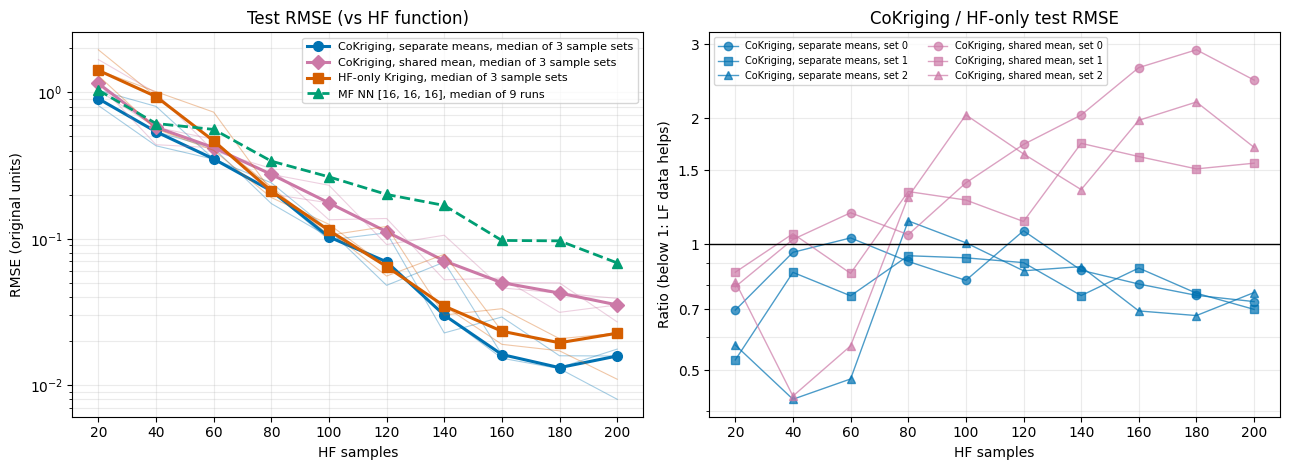

LF fit test RMSE: 0.0007787

CoKriging, separate means test RMSE by HF samples and HF sample set
            set 0   set 1   set 2  median
points_hf                                
20         0.9047  1.0342  0.8124  0.9047
40         0.5382  0.8016  0.4314  0.5382
60         0.4158  0.3510  0.3495  0.3510
80         0.1740  0.2125  0.2411  0.2125
100        0.1029  0.0982  0.1149  0.1029
120        0.0696  0.1098  0.0481  0.0696
140        0.0301  0.0227  0.0693  0.0301
160        0.0153  0.0292  0.0162  0.0162
180        0.0130  0.0159  0.0132  0.0132
200        0.0080  0.0158  0.0176  0.0158

CoKriging, shared mean test RMSE by HF samples and HF sample set
            set 0   set 1   set 2  median
points_hf                                
20         1.0284  1.6740  1.1500  1.1500
40         0.5777  0.9910  0.4390  0.5777
60         0.4774  0.3971  0.4191  0.4191
80         0.2015  0.3023  0.2753  0.2753
100        0.1758  0.1348  0.2319  0.1758
120        0.1118  0.1376  0.0914  0.11

In [5]:
runs = pd.DataFrame(sweep_results)[mf_kriging_helpers.HF_SWEEP_HEADER]
test = runs.pivot_table(index="points_hf", columns=["model", "hf_sample_seed"], values="test_rmse")
medians = runs.groupby(["model", "points_hf"])["test_rmse"].median().unstack("model")

styles = {
    "cokriging_separate": ("#0072B2", "o", "CoKriging, separate means"),
    "cokriging_shared": ("#CC79A7", "D", "CoKriging, shared mean"),
    "hf_only": ("#D55E00", "s", "HF-only Kriging"),
}
ck_models = ["cokriging_separate", "cokriging_shared"]
ratios = {model: test[model] / test["hf_only"] for model in ck_models}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for model, (color, marker, label) in styles.items():
    ax.plot(test.index, test[model].values, color=color, linewidth=0.8, alpha=0.35)
    ax.plot(medians.index, medians[model], color=color, marker=marker, markersize=7, linewidth=2.2,
            label=f"{label}, median of {len(hf_sample_seeds)} sample sets")

nn_file = "mf_nn_hf_sweep_2d_sampling.csv"
nn_medians = None
if os.path.exists(nn_file):
    nn_runs = pd.read_csv(nn_file)
    nn_runs = nn_runs[(nn_runs["points_lf"] == n_lf) & nn_runs["hf_sample_seed"].isin(hf_sample_seeds)]
    nn_medians = nn_runs.groupby("points_hf")["test_rmse"].median()
    ax.plot(nn_medians.index, nn_medians.values, color="#009E73", marker="^", markersize=7, linewidth=2,
            linestyle="--", label="MF NN [16, 16, 16], median of 9 runs")

ax.set_yscale("log")
ax.set_xticks(list(hf_points))
ax.set_title("Test RMSE (vs HF function)")
ax.set_xlabel("HF samples")
ax.set_ylabel("RMSE (original units)")
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8)

ax = axes[1]
set_markers = ["o", "s", "^"]
for model in ck_models:
    color, _, label = styles[model]
    for sample_seed, marker in zip(hf_sample_seeds, set_markers):
        ax.plot(ratios[model].index, ratios[model][sample_seed], color=color, marker=marker, linewidth=1,
                alpha=0.7, label=f"{label}, set {sample_seed}")
ax.axhline(1, color="black", linewidth=1)
ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([0.25, 0.5, 0.7, 1, 1.5, 2, 3, 4]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xticks(list(hf_points))
ax.set_title("CoKriging / HF-only test RMSE")
ax.set_xlabel("HF samples")
ax.set_ylabel("Ratio (below 1: LF data helps)")
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print(f"LF fit test RMSE: {lf_error:.4g}")
print()
for model, (_, _, label) in styles.items():
    table = test[model].copy()
    table.columns = [f"set {c}" for c in table.columns]
    print(f"{label} test RMSE by HF samples and HF sample set")
    print(table.assign(median=medians[model]).round(4).to_string())
    print()

summary = pd.DataFrame({
    "CoKriging, separate": medians["cokriging_separate"],
    "CoKriging, shared": medians["cokriging_shared"],
    "HF-only Kriging": medians["hf_only"],
    "separate / HF-only": ratios["cokriging_separate"].median(axis=1),
    "shared / HF-only": ratios["cokriging_shared"].median(axis=1),
})
if nn_medians is not None:
    summary["MF NN"] = nn_medians
print("Median test RMSE by HF samples (ratios are the median over the sample sets)")
print(summary.round(4).to_string())